In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

output_path = Path('/content/drive/MyDrive/ML_Assignment/Results/Outputs')
output_path.mkdir(parents=True, exist_ok=True)

model_files = {
    'Linear Regression': 'linear_regression_results.csv',
    'Random Forest': 'random_forest_results.csv',
    'Gradient Boosting': 'gradient_boosting_results.csv',
    'XGBoost': 'xgboost_results.csv',
}

models = {}
for name, filename in model_files.items():
    file = output_path / filename
    if not file.exists():
        raise FileNotFoundError(f'Missing {file}. Run the corresponding model notebook and save the results first.')
    models[name] = pd.read_csv(file)
    print(f'Loaded {name}: {filename}')

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(output_path / filename, dpi=200, bbox_inches='tight')
    plt.show()
    plt.close()
    print('Saved:', output_path / filename)


Mounted at /content/drive
Loaded Linear Regression: linear_regression_results.csv


FileNotFoundError: Missing /content/drive/MyDrive/ML_Assignment/Results/Outputs/random_forest_results.csv. Run the corresponding model notebook and save the results first.

## 2. Verify all initial result files

In [ ]:
required = ['Fold', 'Train_RMSE', 'Validation_RMSE', 'Train_MAE',
            'Validation_MAE', 'Train_R2', 'Validation_R2']
for name, frame in models.items():
    missing = set(required) - set(frame.columns)
    assert not missing, f'{name} missing columns: {sorted(missing)}'
    assert sorted(frame['Fold'].tolist()) == [1, 2, 3, 4, 5], f'{name}: expected exactly folds 1–5'
    assert frame[required].notna().all().all(), f'{name}: missing metric values'
    models[name] = frame.sort_values('Fold').reset_index(drop=True)
    print(f'{name}: checked five complete folds')
print('All initial result files passed structural checks.')


Linear Regression: checked five complete folds
Random Forest: checked five complete folds
Gradient Boosting: checked five complete folds
XGBoost: checked five complete folds
All initial result files passed structural checks.


## 3. Initial exploratory model comparison table

In [ ]:
rows = []
for name, frame in models.items():
    rows.append({
        'Model': name,
        'Mean RMSE': frame['Validation_RMSE'].mean(),
        'RMSE SD': frame['Validation_RMSE'].std(),
        'Mean MAE': frame['Validation_MAE'].mean(),
        'MAE SD': frame['Validation_MAE'].std(),
        'Mean R2': frame['Validation_R2'].mean(),
        'R2 SD': frame['Validation_R2'].std(),
    })

initial_comparison = pd.DataFrame(rows).sort_values('Mean RMSE').reset_index(drop=True)
initial_comparison.insert(0, 'Rank', range(1, len(initial_comparison)+1))
display(initial_comparison.round(4))
initial_comparison.to_csv(output_path / 'model_comparison.csv', index=False)
print('Initial comparison saved: model_comparison.csv')
print('Best INITIAL model:', initial_comparison.iloc[0]['Model'])
print('This ranking is exploratory, not the final nested-CV ranking.')


,Rank,Model,Mean RMSE,RMSE SD,Mean MAE,MAE SD,Mean R2,R2 SD
0,1,XGBoost,0.1301,0.0207,0.0848,0.0061,0.8886,0.0469
1,2,Gradient Boosting,0.1349,0.0199,0.0878,0.0073,0.8811,0.0447
2,3,Random Forest,0.1442,0.0200,0.0961,0.0080,0.8652,0.0465
3,4,Linear Regression,0.1554,0.0474,0.0921,0.0049,0.8305,0.1286


Initial comparison saved: model_comparison.csv
Best INITIAL model: XGBoost
This ranking is exploratory, not the final nested-CV ranking.


## 4. Comparison graphs (saved as PNG for the report)

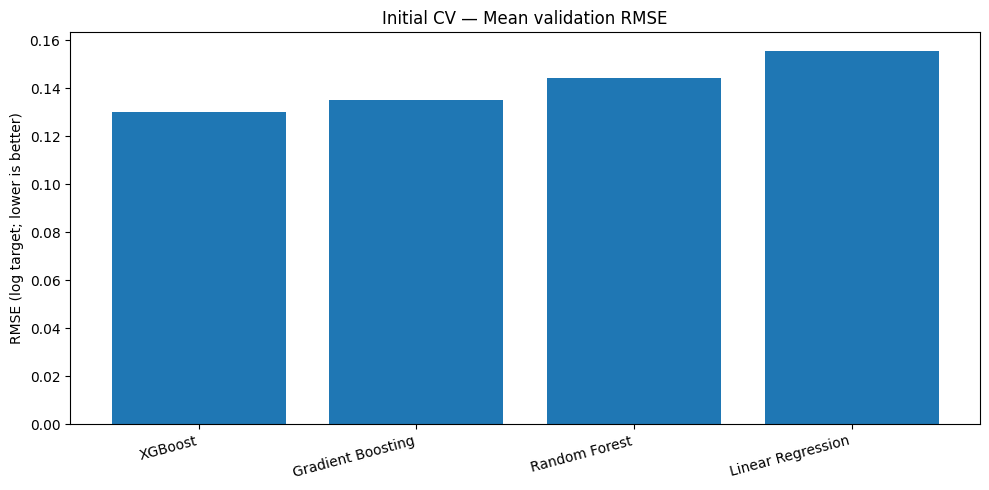

Saved: /content/drive/MyDrive/ML_Assignment/Results/Outputs/initial_model_rmse.png


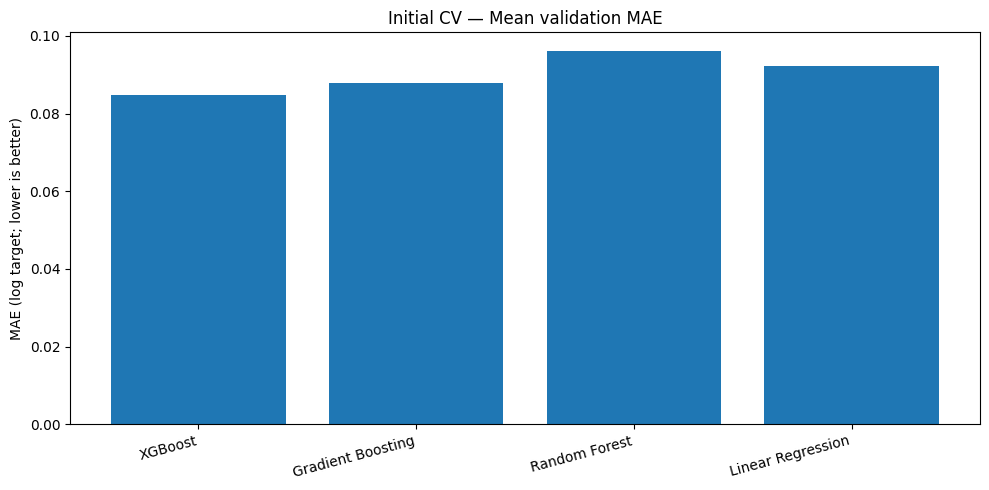

Saved: /content/drive/MyDrive/ML_Assignment/Results/Outputs/initial_model_mae.png


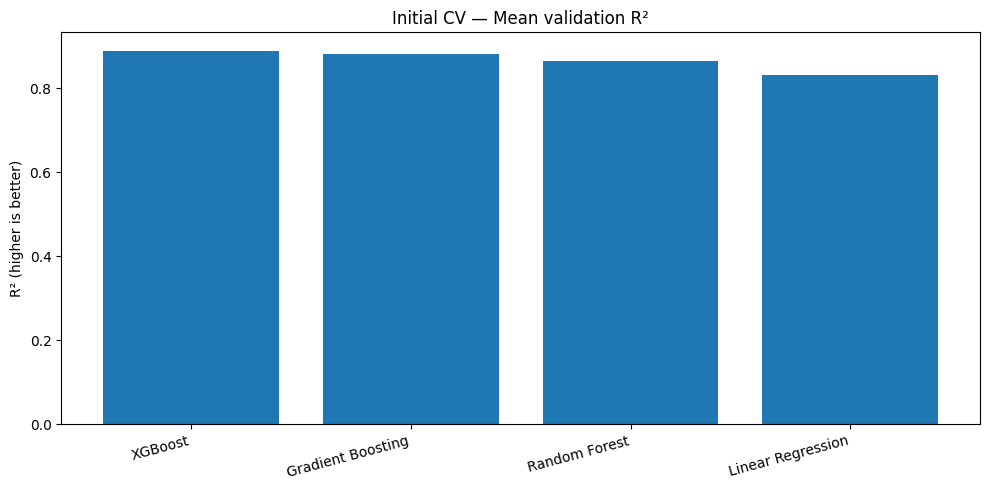

Saved: /content/drive/MyDrive/ML_Assignment/Results/Outputs/initial_model_r2.png


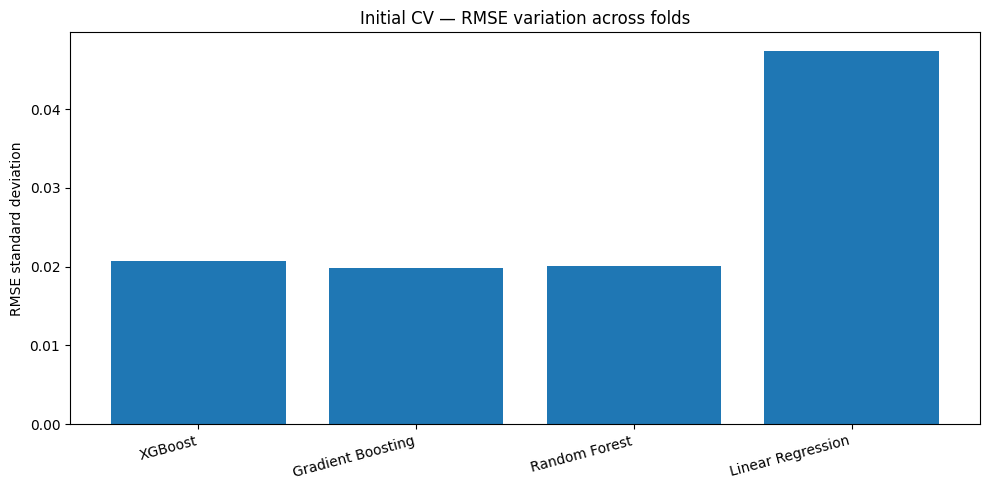

Saved: /content/drive/MyDrive/ML_Assignment/Results/Outputs/initial_model_rmse_sd.png


In [ ]:
for metric, title, filename, ylabel in [
    ('Mean RMSE', 'Initial CV — Mean validation RMSE', 'initial_model_rmse.png', 'RMSE (log target; lower is better)'),
    ('Mean MAE', 'Initial CV — Mean validation MAE', 'initial_model_mae.png', 'MAE (log target; lower is better)'),
    ('Mean R2', 'Initial CV — Mean validation R²', 'initial_model_r2.png', 'R² (higher is better)'),
    ('RMSE SD', 'Initial CV — RMSE variation across folds', 'initial_model_rmse_sd.png', 'RMSE standard deviation'),
]:
    plt.figure(figsize=(10, 5))
    plt.bar(initial_comparison['Model'], initial_comparison[metric])
    plt.title(title)
    plt.ylabel(ylabel)
    plt.xticks(rotation=15, ha='right')
    save_plot(filename)


## 5. Initial fold-by-fold RMSE (models share five labelled folds)

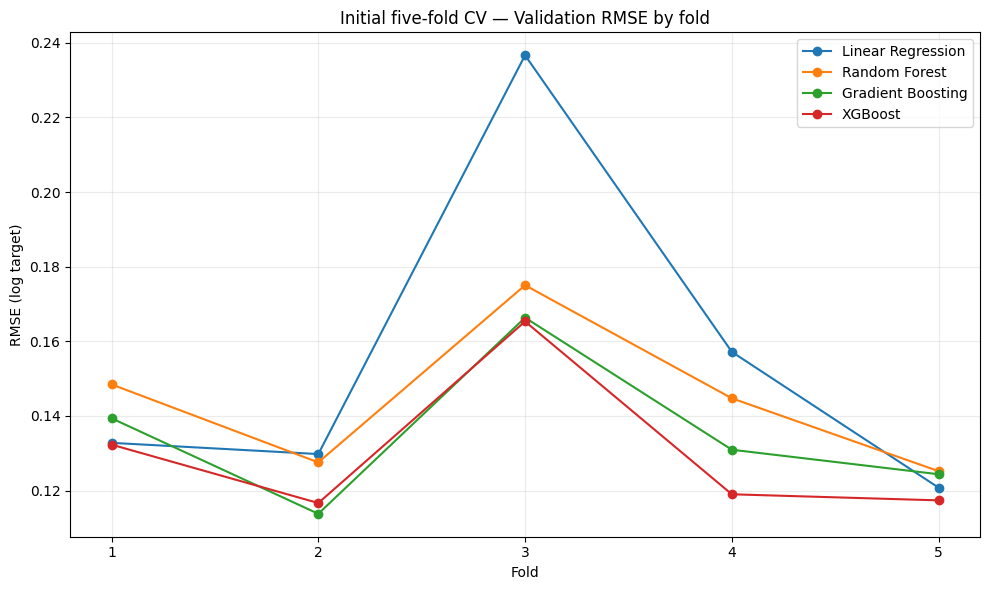

Saved: /content/drive/MyDrive/ML_Assignment/Results/Outputs/initial_five_fold_rmse.png


In [ ]:
plt.figure(figsize=(10, 6))
for name, frame in models.items():
    plt.plot(frame['Fold'], frame['Validation_RMSE'], marker='o', label=name)
plt.title('Initial five-fold CV — Validation RMSE by fold')
plt.xlabel('Fold')
plt.ylabel('RMSE (log target)')
plt.xticks([1, 2, 3, 4, 5])
plt.legend()
plt.grid(alpha=0.25)
save_plot('initial_five_fold_rmse.png')


## 6. Initial training vs validation errors and generalization gap

Larger gaps **suggest** greater overfitting, but alone do not prove it. These are exploratory training/validation summaries.

,Model,Train RMSE,Validation RMSE,RMSE Gap
0,XGBoost,0.0572,0.1301,0.0729
1,Gradient Boosting,0.0694,0.1349,0.0656
2,Random Forest,0.0533,0.1442,0.0909
3,Linear Regression,0.0952,0.1554,0.0602


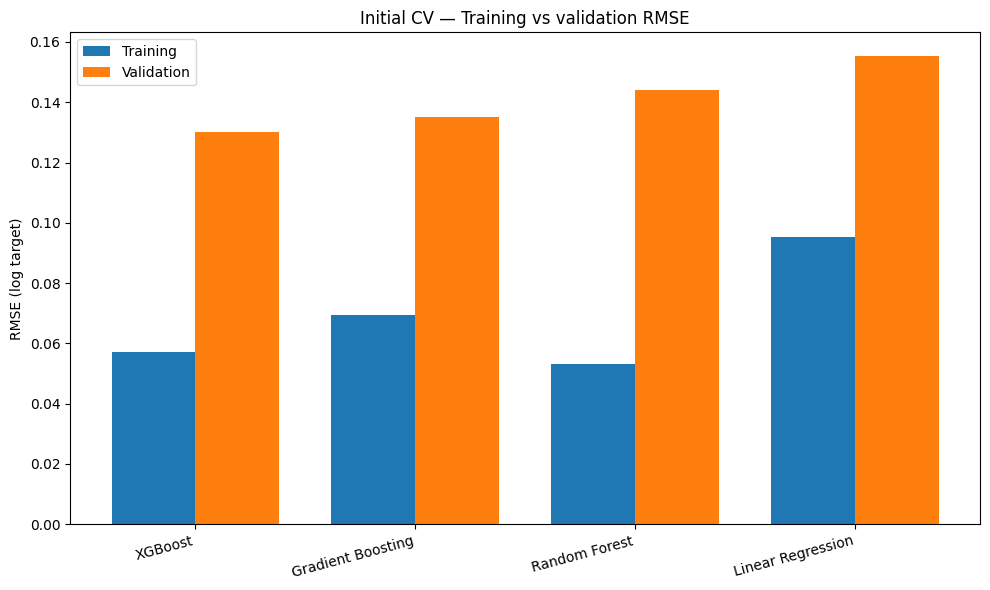

Saved: /content/drive/MyDrive/ML_Assignment/Results/Outputs/initial_train_vs_validation_rmse.png


In [ ]:
gap_rows = []
for name, frame in models.items():
    train_rmse = frame['Train_RMSE'].mean()
    valid_rmse = frame['Validation_RMSE'].mean()
    gap_rows.append({'Model':name, 'Train RMSE':train_rmse, 'Validation RMSE':valid_rmse,
                     'RMSE Gap':valid_rmse-train_rmse})
gap_df=pd.DataFrame(gap_rows).sort_values('Validation RMSE').reset_index(drop=True)
display(gap_df.round(4))
gap_df.to_csv(output_path / 'initial_generalization_gap.csv', index=False)

idx = np.arange(len(gap_df))
w = 0.38
plt.figure(figsize=(10, 6))
plt.bar(idx-w/2, gap_df['Train RMSE'], width=w, label='Training')
plt.bar(idx+w/2, gap_df['Validation RMSE'], width=w, label='Validation')
plt.xticks(idx, gap_df['Model'], rotation=15, ha='right')
plt.ylabel('RMSE (log target)')
plt.title('Initial CV — Training vs validation RMSE')
plt.legend()
save_plot('initial_train_vs_validation_rmse.png')


## 7. FINAL nested cross-validation comparison

**This is the comparison to use when selecting the final model.** It was computed separately using original labelled data with preprocessing and supervised feature selection inside nested cross-validation.

,Model,Mean_RMSE,RMSE_SD,Mean_MAE,Mean_R2
0,Gradient Boosting,0.1297,0.0174,0.0853,0.8897
1,XGBoost,0.1311,0.0182,0.0852,0.8872


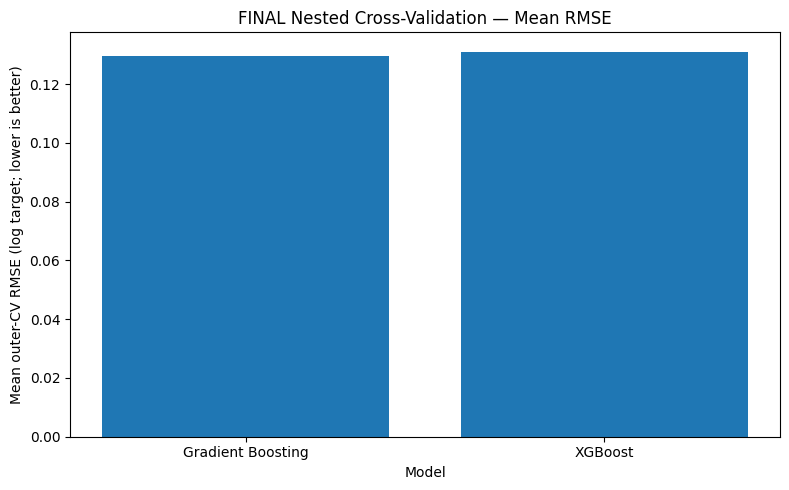

Saved: /content/drive/MyDrive/ML_Assignment/Results/Outputs/final_nested_cv_rmse.png
Preferred model by FINAL nested-CV mean RMSE: Gradient Boosting
Mean RMSE: 0.1297
Mean MAE: 0.0853
Mean R²: 0.8897
Note: small differences between models do not establish a significant performance advantage.


In [ ]:
nested_path = output_path / 'nested_cv_final_results.csv'
if not nested_path.exists():
    raise FileNotFoundError(f'{nested_path} not found. Run Final_Model_Validation.ipynb first.')

final_comparison = pd.read_csv(nested_path)
needed = {'Model', 'Mean_RMSE', 'RMSE_SD', 'Mean_MAE', 'Mean_R2'}
assert needed.issubset(final_comparison.columns), ('Final nested results missing: ' +
    ', '.join(sorted(needed - set(final_comparison.columns))))
assert final_comparison[sorted(needed-{'Model'})].notna().all().all(), 'Final results contain missing numeric metrics'
final_comparison = final_comparison.sort_values('Mean_RMSE').reset_index(drop=True)
display(final_comparison.round(4))

plt.figure(figsize=(8,5))
plt.bar(final_comparison['Model'], final_comparison['Mean_RMSE'])
plt.title('FINAL Nested Cross-Validation — Mean RMSE')
plt.xlabel('Model')
plt.ylabel('Mean outer-CV RMSE (log target; lower is better)')
save_plot('final_nested_cv_rmse.png')

winner=final_comparison.iloc[0]
print('Preferred model by FINAL nested-CV mean RMSE:',winner['Model'])
print('Mean RMSE:',round(winner['Mean_RMSE'],4))
print('Mean MAE:',round(winner['Mean_MAE'],4))
print('Mean R²:',round(winner['Mean_R2'],4))
print('Note: small differences between models do not establish a significant performance advantage.')
